# 03. 라이다 인지 — 스캔 데이터 처리 & 장애물 감지

`lidar_perception_func_lib.py` 의 실제 함수를 사용합니다:
- `detect_object` — 특정 각도·거리 범위 안에 물체가 있는지
- `rotate_lidar_data` / `flip_lidar_data` — 센서 장착 방향 보정
- `StabilityDetector` — 순간 노이즈를 걸러 안정적으로 감지

> **참고:** 이 라이브러리는 실제 RPLidar 하드웨어용 `serial` 모듈을 import 합니다.
> 하드웨어가 없어도 실습할 수 있도록, 아래에서 `serial` 을 가벼운 더미로 대체한 뒤 불러옵니다.


## 공통 설정 실행
아래 셀은 **모든 노트북 맨 위에서 한 번 실행**합니다. 프로젝트 루트를 찾고, 실제 코드가 있는 `lib` 폴더들을 import 경로에 등록하며, 이미지 표시 헬퍼(`show`, `show_row`)를 정의합니다.


In [1]:
# === 공통 설정: 프로젝트 루트 찾기 + 라이브러리 경로 등록 ===
import sys, math
from pathlib import Path
import numpy as np
import cv2
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as _fm

# 그래프 한글 라벨이 깨지지 않도록 한글 폰트 지정 (Windows=맑은고딕 / Linux=나눔고딕)
for _f in [r'C:\Windows\Fonts\malgun.ttf', '/usr/share/fonts/truetype/nanum/NanumGothic.ttf']:
    try:
        _fm.fontManager.addfont(_f)
        matplotlib.rcParams['font.family'] = _fm.FontProperties(fname=_f).get_name()
        break
    except Exception:
        pass
matplotlib.rcParams['axes.unicode_minus'] = False

def find_root(start):
    p = Path(start).resolve()
    for cand in [p, *p.parents]:
        if (cand / 'src' / 'camera_perception_pkg').exists():
            return cand
    raise RuntimeError('ros3_ws 루트를 찾지 못했습니다. 노트북을 education_notebooks/ 안에서 실행하세요.')

ROOT = find_root(Path.cwd())
print('프로젝트 루트:', ROOT)

# 각 패키지의 lib 경로를 import 경로에 등록
CAM_LIB   = ROOT/'src'/'camera_perception_pkg'/'camera_perception_pkg'/'lib'
LIDAR_LIB = ROOT/'src'/'lidar_perception_pkg'/'lidar_perception_pkg'/'lib'
DEC_LIB   = ROOT/'src'/'decision_making_pkg'/'decision_making_pkg'/'lib'
SER_LIB   = ROOT/'src'/'serial_communication_pkg'/'serial_communication_pkg'/'lib'
SAMPLES   = CAM_LIB/'Collected_Datasets'/'sample_dataset'
for p in (CAM_LIB, LIDAR_LIB, DEC_LIB, SER_LIB):
    sys.path.insert(0, str(p))

# Jupyter/터미널 어디서든 이미지를 인라인으로 보기 위한 헬퍼
def show(img, title='', cmap=None, figsize=(6,4)):
    plt.figure(figsize=figsize)
    if img.ndim == 3:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))   # OpenCV는 BGR, matplotlib은 RGB
    else:
        plt.imshow(img, cmap=cmap or 'gray')
    plt.title(title); plt.axis('off'); plt.tight_layout(); plt.show()

def show_row(imgs, titles=None, cmap=None, figsize=(14,4)):
    n = len(imgs); titles = titles or ['']*n
    plt.figure(figsize=figsize)
    for i,(im,t) in enumerate(zip(imgs, titles)):
        ax = plt.subplot(1, n, i+1)
        if im.ndim == 3: ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        else: ax.imshow(im, cmap=cmap or 'gray')
        ax.set_title(t); ax.axis('off')
    plt.tight_layout(); plt.show()

print('OpenCV', cv2.__version__, '| NumPy', np.__version__)


프로젝트 루트: C:\Users\asus\Documents\workspace\ros3_ws
OpenCV 5.0.0 | NumPy 2.4.6


## 실제 라이브러리 불러오기 (serial 더미 주입)


In [2]:
import types
if 'serial' not in sys.modules:
    sys.modules['serial'] = types.ModuleType('serial')  # 하드웨어용 stub (실습엔 불필요)
import lidar_perception_func_lib as lp
print('불러온 함수:', [n for n in ('detect_object','rotate_lidar_data','flip_lidar_data','StabilityDetector')])



 ____    ___   ____    ____  
|  _ \  / _ \ / ___|  |___ \ 
| |_) || | | |\___ \    __) |
|  _ < | |_| | ___) |  / __/ 
|_| \_\ \___/ |____/  |_____|
                             
    _            _                 
   / \    _   _ | |_   ___         
  / _ \  | | | || __| / _ \  _____ 
 / ___ \ | |_| || |_ | (_) ||_____|
/_/   \_\ \__,_| \__| \___/        
                                   
__     __       _      _        _       
\ \   / /  ___ | |__  (_)  ___ | |  ___ 
 \ \ / /  / _ \| '_ \ | | / __|| | / _   \ V /  |  __/| | | || || (__ | ||  __/
   \_/    \___||_| |_||_| \___||_| \___|  


ROS2 기반 자율주행 설계 및 구현
Sungkyunkwan University Automation Lab.
------------------Authors------------------
Hyeong-Keun Hong <whaihong@g.skku.edu>
Jinsun Lee <with23skku@g.skku.edu>
Siwoo Lee <edenlee@g.skku.edu>
Jae-Wook Jeon <jwjeon@skku.edu>
------------------------------------------
불러온 함수: ['detect_object', 'rotate_lidar_data', 'flip_lidar_data', 'StabilityDetector']


## 1) 가상 라이다 스캔 만들기
2D 라이다는 360도를 한 바퀴 돌며 각 각도의 **거리값**을 배열로 줍니다(`ranges[0..359]`).
장애물이 없으면 큰 값(예: 무한대/최대거리), 있으면 작은 거리값이 들어옵니다.


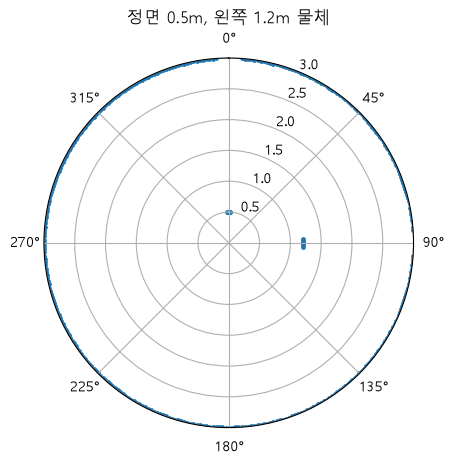

In [3]:
def make_scan(obstacles, n=360, empty=float('inf')):
    # obstacles: (각도, 거리) 리스트. 해당 각도 주변에 물체를 심는다.
    ranges = [empty]*n
    for ang, dist in obstacles:
        for d in range(-3, 4):                 # 물체는 폭이 있으므로 ±3도
            ranges[(ang+d) % n] = dist
    return ranges

# 정면(0도)에 0.5m, 왼쪽(90도)에 1.2m 물체
ranges = make_scan([(0, 0.5), (90, 1.2)])

def polar_plot(ranges, title='LiDAR scan', rmax=3.0):
    angs = np.deg2rad(np.arange(len(ranges)))
    r = np.array([min(x, rmax) if np.isfinite(x) else rmax for x in ranges])
    ax = plt.subplot(111, projection='polar')
    ax.set_theta_zero_location('N'); ax.set_theta_direction(-1)
    ax.scatter(angs, r, s=6); ax.set_rmax(rmax); ax.set_title(title); plt.show()

polar_plot(ranges, '정면 0.5m, 왼쪽 1.2m 물체')


## 2) 장애물 감지 — `detect_object`
`detect_object(ranges, start_angle, end_angle, range_min, range_max)`:
지정한 **각도 범위** 안에서 **거리 범위**(range_min~range_max)에 드는 값이 하나라도 있으면 `True`.

- 정면 감지는 보통 `start_angle=350, end_angle=10` 처럼 0도를 감싸는 범위를 씁니다.


In [4]:
front = lp.detect_object(ranges, start_angle=350, end_angle=10, range_min=0.1, range_max=0.8)
left  = lp.detect_object(ranges, start_angle=80,  end_angle=100, range_min=0.1, range_max=2.0)
right = lp.detect_object(ranges, start_angle=260, end_angle=280, range_min=0.1, range_max=2.0)
print(f'정면(350~10도, ~0.8m): {front}')
print(f'왼쪽(80~100도, ~2.0m): {left}')
print(f'오른쪽(260~280도, ~2.0m): {right}')


정면(350~10도, ~0.8m): True
왼쪽(80~100도, ~2.0m): True
오른쪽(260~280도, ~2.0m): False


## 3) 스캔 방향 보정 — `rotate_lidar_data` / `flip_lidar_data`
라이다를 거꾸로/돌려서 장착하면 각도 기준이 어긋납니다. 이를 소프트웨어로 보정합니다.
이 함수들은 **ROS 메시지 객체**(`.ranges`, `.intensities` 리스트를 가진)를 입력받으므로,
간단한 가짜 메시지 클래스를 만들어 사용합니다.


In [5]:
class MockScanMsg:
    def __init__(self, ranges):
        self.ranges = list(ranges)
        self.intensities = [0.0]*len(ranges)

# rotate: 배열을 offset 만큼 회전 (장착 각도 오프셋 보정)
msg = MockScanMsg(make_scan([(0, 0.5)]))
rotated = lp.rotate_lidar_data(MockScanMsg(msg.ranges), offset=90)
print('원래 0도에 있던 물체가 rotate(90) 후 어디로?')
print('  회전 후 270도 거리값:', rotated.ranges[270])   # 0 - 90 = -90 -> 270

# flip: pivot_angle 기준 좌우 반전 (거울상 장착 보정)
flipped = lp.flip_lidar_data(MockScanMsg(make_scan([(30,0.5)])), pivot_angle=0)
print('flip(pivot=0): 30도 물체 -> ', [i for i,v in enumerate(flipped.ranges) if np.isfinite(v)])


원래 0도에 있던 물체가 rotate(90) 후 어디로?
  회전 후 270도 거리값: 0.5
flip(pivot=0): 30도 물체 ->  [327, 328, 329, 330, 331, 332, 333]


## 4) 안정적 감지 — `StabilityDetector`
라이다 값은 순간적으로 튀는 노이즈가 있습니다. `StabilityDetector(consec_count)` 는
**연속 N번** 같은 결과가 나와야 상태를 바꿔, 오탐/미탐을 줄입니다.


In [6]:
detector = lp.StabilityDetector(consec_count=3)   # 3번 연속이어야 상태 변경

# 노이즈가 섞인 감지 시퀀스 (True=물체 있음)
raw_sequence = [False,False,True,False,True,True,True,True,False,True,False,False,False,True]
print(' raw -> stable')
for raw in raw_sequence:
    stable = detector.check_consecutive_detections(raw)
    print(f'  {str(raw):5s} -> {stable}')


 raw -> stable
  False -> False
  False -> False
  True  -> False
  False -> False
  True  -> False
  True  -> False
  True  -> True
  True  -> True
  False -> True
  True  -> True
  False -> True
  False -> True
  False -> False
  True  -> False


위 결과에서 단발성 `True`(노이즈)는 무시되고, **3번 연속 True**가 되어야 비로소 상태가 켜지는 것을 확인하세요.


---
## 🎯 미션 1 — 감지 구역 바꾸기
정면 물체를 감지하는 각도/거리 범위를 바꿔, 위 `ranges` 의 왼쪽(90도) 물체만 잡도록
`detect_object` 인자를 완성하세요.


In [7]:
# TODO: 90도 부근 1.2m 물체만 True가 되도록 인자를 채우세요
hit = lp.detect_object(ranges, start_angle=..., end_angle=..., range_min=..., range_max=...)
print(hit)


TypeError: '>' not supported between instances of 'ellipsis' and 'ellipsis'

**▶ 정답 예시**


In [ ]:
hit = lp.detect_object(ranges, start_angle=85, end_angle=95, range_min=0.1, range_max=1.5)
print('왼쪽 물체 감지:', hit)


## 🎯 미션 2 — `consec_count` 튜닝
`consec_count` 를 1, 2, 5 로 바꾸면 노이즈 억제가 어떻게 달라질까요?
같은 `raw_sequence` 로 비교해 보세요.


In [ ]:
# TODO: for 문으로 여러 consec_count 를 비교하세요
for cc in [1, 2, 3, 5]:
    d = lp.StabilityDetector(consec_count=cc)
    out = [d.check_consecutive_detections(r) for r in raw_sequence]
    changes = sum(1 for a,b in zip(out, out[1:]) if a!=b)
    print(f'consec_count={cc}: 상태변화 {changes}회  {out}')


값이 클수록 상태가 잘 안 바뀌어 **안정적이지만 반응이 느려집니다**. 트레이드오프를 관찰하세요.


---
✅ 라이다 인지 완료! 마지막은 **`04_시리얼_통합.ipynb`** 입니다.
